# Squat Form Classification

Classifying squat form (good vs. bad) using pose keypoint sequences.

Dataset: Mendeley Multi-View Fitness Exercise Videos (DOI: 10.17632/kgbb3yn47p.1)

## 0. Setup

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    balanced_accuracy_score,
)

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Paths
ROOT = Path.cwd().parent          # D:\DL  (notebook lives in notebooks/)
RAW  = ROOT / "data" / "raw"
PROC = ROOT / "data" / "processed"
OUT  = ROOT / "outputs"

for d in (RAW, PROC, OUT):
    d.mkdir(parents=True, exist_ok=True)

MANIFEST = ROOT / "data" / "metadata.csv"

# Hyperparameters
N_FRAMES = 16       # Uniformly-sampled frames per clip
IMGSZ    = 384      # Pose-estimator input resolution (px)

print(f"Project root : {ROOT}")
print(f"Manifest     : {MANIFEST}  (exists: {MANIFEST.exists()})")
print(f"Frames/clip  : {N_FRAMES}")
print(f"Pose img size: {IMGSZ}")

Project root : D:\DL
Manifest     : D:\DL\data\metadata.csv  (exists: True)
Frames/clip  : 16
Pose img size: 384


## 1. Manifest & Video Filtering

In [5]:
# Load manifest
df = pd.read_csv(MANIFEST, dtype=str).fillna("")

# Sanity checks on required columns
required_cols = {"video_path", "label", "subject_id", "exercise", "view"}
assert required_cols <= set(df.columns), f"Missing columns: {required_cols - set(df.columns)}"

# Normalize text fields
df["label"]    = df["label"].str.lower().str.strip()
df["exercise"] = df["exercise"].str.lower().str.strip()

# Filter to squat clips
df = df[df["exercise"].str.contains("squat", regex=False)].copy()

# Verify integrity
assert len(df) > 0, "No squat clips found!"
assert set(df["label"].unique()) == {"good", "bad"}, "Need both good and bad labels"
assert df["video_path"].apply(lambda p: (ROOT / p).exists()).all(), "Some video files are missing"

print(f"{len(df)} squat clips from {df['subject_id'].nunique()} subjects\n")
display(df.groupby(["label", "view"]).size().unstack(fill_value=0))

150 squat clips from 25 subjects



view,diagonal,front,side
label,,,
bad,25,25,25
good,25,25,25


## 2. Pose Feature Extraction (YOLOv8n-pose)

Extracting 17 COCO keypoints per frame normalized by person bounding box.

In [29]:
import cv2
import torch
from ultralytics import YOLO

# Pick GPU if available, otherwise CPU
device = 0 if torch.cuda.is_available() else "cpu"
print(f"Pose-estimation device: {'cuda:0' if device == 0 else 'cpu'}")

# Load the pretrained pose model (downloads automatically on first run)
pose_model = YOLO("yolov8n-pose.pt")

CACHE = PROC / "squat_pose_16f_v1.npz"

Pose-estimation device: cuda:0


In [30]:
def extract_pose_sequence(video_path: str) -> np.ndarray | None:
    """
    Extract a pose sequence of shape (N_FRAMES, 51) from a video.

    Extracts a normalized sequence of shape (N_FRAMES, 51).

    Returns None if the video cannot be read.
    """
    cap = cv2.VideoCapture(str(video_path))
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if total_frames <= 0:
        cap.release()
        return None

    # pre-allocate sequence array
    seq = np.zeros((N_FRAMES, 17, 3), dtype=np.float32)

    # uniform sampling across video
    sample_indices = np.linspace(0, total_frames - 1, N_FRAMES).round().astype(int)

    for i, frame_idx in enumerate(sample_indices):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_idx))
        ok, frame = cap.read()
        if not ok:
            continue

        # Run pose estimation
        result = pose_model.predict(frame, imgsz=IMGSZ, device=device, verbose=False)[0]

        if result.keypoints is None or len(result.keypoints.xy) == 0:
            continue  # No person detected in this frame

        # extract keypoints
        xy   = result.keypoints.xy.cpu().numpy()    # (n_people, 17, 2)
        conf = result.keypoints.conf.cpu().numpy()  # (n_people, 17)

        # select person with highest mean confidence
        best_person = int(conf.mean(axis=1).argmax())
        box = result.boxes.xyxy[best_person].cpu().numpy()  # [x1, y1, x2, y2]
        pts = xy[best_person]  # (17, 2)

        # Normalize by bounding box (prevents scale/position variation)
        box_w = max(float(box[2] - box[0]), 1.0)
        box_h = max(float(box[3] - box[1]), 1.0)

        seq[i, :, 0] = (pts[:, 0] - box[0]) / box_w   # normalized x
        seq[i, :, 1] = (pts[:, 1] - box[1]) / box_h   # normalized y
        seq[i, :, 2] = conf[best_person]               # confidence

    cap.release()

    # Interpolate over frames with missing detections
    for j in range(17):
        valid = seq[:, j, 2] > 0  # frames where this keypoint was detected
        if valid.any():
            for k in range(3):  # interpolate x, y, and confidence
                seq[:, j, k] = np.interp(
                    np.arange(N_FRAMES),
                    np.flatnonzero(valid),
                    seq[valid, j, k],
                )

    # Flatten: (N_FRAMES, 17, 3) → (N_FRAMES, 51)
    return seq.reshape(N_FRAMES, 51)

In [27]:
if CACHE.exists():
    # Load cached features
    z = np.load(CACHE, allow_pickle=True)
    X      = z["X"]
    y      = z["y"]
    groups = z["groups"]
    views  = z["views"]
    paths  = z["paths"]
    print(f"Loaded cached features from {CACHE}")

else:
    # Extract features from all squat videos
    X_list, y_list, group_list, view_list, path_list = [], [], [], [], []
    failures = []

    for row in df.itertuples(index=False):
        features = extract_pose_sequence(ROOT / row.video_path)

        # Skip if extraction failed or avg confidence is too low
        if features is None or features[:, 2::3].mean() < 0.05:
            failures.append(row.video_path)
            continue

        X_list.append(features)
        y_list.append(int(row.label == "good"))  # 0 = bad, 1 = good
        group_list.append(row.subject_id)
        view_list.append(row.view)
        path_list.append(row.video_path)

    # Convert to arrays
    X      = np.asarray(X_list, dtype=np.float32)
    y      = np.asarray(y_list, dtype=np.int64)
    groups = np.asarray(group_list)
    views  = np.asarray(view_list)
    paths  = np.asarray(path_list)

    # Save to cache
    np.savez_compressed(CACHE, X=X, y=y, groups=groups, views=views, paths=paths)
    print(f"Pose extraction complete. Failures: {len(failures)}")
    if failures:
        print("Failed videos:", failures)

print(f"Feature matrix shape: {X.shape}  (clips, frames, features)")
print(f"Usable subjects: {len(np.unique(groups))}")
print(f"Label distribution: bad={int((y == 0).sum())}, good={int((y == 1).sum())}")

Loaded cached features from D:\DL\data\processed\squat_pose_16f_v1.npz
Feature matrix shape: (150, 16, 51)  (clips, frames, features)
Usable subjects: 25
Label distribution: bad=75, good=75


## 3. Subject-Grouped Train / Val / Test Splits

In [16]:
# split test set (20% subjects)
gss_test = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
trainval_idx, test_idx = next(gss_test.split(X, y, groups))

# split val set (20% subjects)
gss_val = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED + 1)
rel_train_idx, rel_val_idx = next(gss_val.split(
    X[trainval_idx], y[trainval_idx], groups[trainval_idx]
))

# Map relative indices back to the original array indices
train_idx = trainval_idx[rel_train_idx]
val_idx   = trainval_idx[rel_val_idx]

# Verify zero subject leakage
train_subjects = set(groups[train_idx])
val_subjects   = set(groups[val_idx])
test_subjects  = set(groups[test_idx])

assert not (train_subjects & val_subjects), "Subject leak: train ∩ val!"
assert not (train_subjects & test_subjects), "Subject leak: train ∩ test!"
assert not (val_subjects   & test_subjects), "Subject leak: val ∩ test!"

# summary
for name, idx in [("Train", train_idx), ("Validation", val_idx), ("Test", test_idx)]:
    labels_in_split = dict(zip(*np.unique(y[idx], return_counts=True)))
    subjects_in_split = sorted(set(groups[idx]))
    print(f"{name:12s}  {len(idx):3d} clips  "
          f"labels={labels_in_split}  "
          f"subjects={subjects_in_split}")

Train          90 clips  labels={np.int64(0): np.int64(45), np.int64(1): np.int64(45)}  subjects=[np.str_('subject_002'), np.str_('subject_003'), np.str_('subject_004'), np.str_('subject_005'), np.str_('subject_006'), np.str_('subject_010'), np.str_('subject_011'), np.str_('subject_014'), np.str_('subject_015'), np.str_('subject_016'), np.str_('subject_018'), np.str_('subject_020'), np.str_('subject_021'), np.str_('subject_022'), np.str_('subject_023')]
Validation     30 clips  labels={np.int64(0): np.int64(15), np.int64(1): np.int64(15)}  subjects=[np.str_('subject_007'), np.str_('subject_008'), np.str_('subject_013'), np.str_('subject_019'), np.str_('subject_026')]
Test           30 clips  labels={np.int64(0): np.int64(15), np.int64(1): np.int64(15)}  subjects=[np.str_('subject_001'), np.str_('subject_009'), np.str_('subject_012'), np.str_('subject_017'), np.str_('subject_024')]


## 4. Models (MLP, GRU, TCN)

In [31]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(SEED)
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training device: {dev}")


# MLP
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(51, 128),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(128, 2),
        )

    def forward(self, x):
        # x shape: (batch, 16, 51)  →  pick the middle frame
        mid = x[:, x.shape[1] // 2]  # (batch, 51)
        return self.net(mid)


# GRU
class GRU(nn.Module):
    def __init__(self):
        super().__init__()
        self.rnn = nn.GRU(
            input_size=51,
            hidden_size=96,
            batch_first=True,
            bidirectional=True,
        )
        self.head = nn.Linear(192, 2)  # 96 * 2 directions

    def forward(self, x):
        # x shape: (batch, 16, 51)
        out, _ = self.rnn(x)       # (batch, 16, 192)
        pooled = out.mean(dim=1)   # mean over time → (batch, 192)
        return self.head(pooled)


# TCN
class TCNBlock(nn.Module):
    """Residual block: two dilated Conv1d layers with skip connection."""

    def __init__(self, in_ch, out_ch, dilation):
        super().__init__()
        self.conv_path = nn.Sequential(
            nn.Conv1d(in_ch, out_ch, kernel_size=3, padding=dilation, dilation=dilation),
            nn.BatchNorm1d(out_ch),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Conv1d(out_ch, out_ch, kernel_size=3, padding=dilation, dilation=dilation),
            nn.BatchNorm1d(out_ch),
            nn.GELU(),
        )
        # 1x1 conv to match dimensions for the skip connection
        self.skip = nn.Conv1d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x):
        return self.conv_path(x) + self.skip(x)


class TCN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            TCNBlock(51,  64,  dilation=1),  # receptive field grows
            TCNBlock(64,  96,  dilation=2),  # with increasing dilation
            TCNBlock(96,  128, dilation=4),
            nn.AdaptiveAvgPool1d(1),          # pool over time
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128, 2),
        )

    def forward(self, x):
        # x shape: (batch, 16, 51)  →  Conv1d expects (batch, channels, time)
        return self.net(x.transpose(1, 2))

Training device: cuda


## 5. Training

In [32]:
def make_loader(indices, shuffle=False):
    """Create a DataLoader from the global X, y arrays using given indices."""
    dataset = TensorDataset(
        torch.tensor(X[indices]),
        torch.tensor(y[indices]),
    )
    return DataLoader(dataset, batch_size=32, shuffle=shuffle)


def train_model(model, max_epochs=60, patience=10):
    """
    Train a model with early stopping on validation macro-F1.

    Returns:
        model: The model loaded with its best checkpoint weights.
        best_f1: The best validation macro-F1 score achieved.
    """
    model = model.to(dev)

    # Class-weighted loss
    class_counts = np.bincount(y[train_idx], minlength=2)
    class_weights = torch.tensor(
        len(train_idx) / (2 * np.maximum(class_counts, 1)),
        dtype=torch.float32,
        device=dev,
    )
    criterion = nn.CrossEntropyLoss(weight=class_weights)

    optimizer = torch.optim.AdamW(
        model.parameters(), lr=1e-3, weight_decay=1e-3
    )

    best_f1 = -1.0
    best_state = None
    wait = 0

    train_loader = make_loader(train_idx, shuffle=True)
    val_loader   = make_loader(val_idx, shuffle=False)

    for epoch in range(max_epochs):
        # Train
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(dev), yb.to(dev)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

        # Validate
        model.eval()
        all_preds, all_true = [], []
        with torch.no_grad():
            for xb, yb in val_loader:
                preds = model(xb.to(dev)).argmax(dim=1).cpu().numpy()
                all_preds.extend(preds)
                all_true.extend(yb.numpy())

        val_f1 = f1_score(all_true, all_preds, average="macro", zero_division=0)

        # Early stopping
        if val_f1 > best_f1:
            best_f1 = val_f1
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1

        if wait >= patience:
            print(f"  Early stop at epoch {epoch + 1}")
            break

    # Restore best checkpoint
    model.load_state_dict(best_state)
    return model, best_f1

In [33]:
# Train all three models
models = {}

for name, ModelClass in [("MLP", MLP), ("GRU", GRU), ("TCN", TCN)]:
    print(f"\nTraining {name}...")
    model, val_f1 = train_model(ModelClass())
    models[name] = model
    print(f"  {name}  best validation macro-F1 = {val_f1:.4f}")


Training MLP...
  Early stop at epoch 16
  MLP  best validation macro-F1 = 0.5249

Training GRU...
  Early stop at epoch 17
  GRU  best validation macro-F1 = 0.5333

Training TCN...
  Early stop at epoch 27
  TCN  best validation macro-F1 = 0.6606


## 6. Evaluation

In [34]:
def predict(model, indices):
    """
    Run inference on the given indices.

    Returns:
        y_true: Ground-truth labels
        y_pred: Predicted class labels
        y_prob: Predicted probability for the 'good' class
    """
    model.eval()
    all_preds, all_probs, all_true = [], [], []

    with torch.no_grad():
        for xb, yb in make_loader(indices):
            logits = model(xb.to(dev))
            all_preds.extend(logits.argmax(dim=1).cpu().numpy())
            all_probs.extend(logits.softmax(dim=1)[:, 1].cpu().numpy())
            all_true.extend(yb.numpy())

    return np.array(all_true), np.array(all_preds), np.array(all_probs)

In [35]:
# Evaluate all models + majority baseline
results_rows = []

for name, model in models.items():
    y_true, y_pred, y_prob = predict(model, test_idx)

    macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
    bal_acc  = balanced_accuracy_score(y_true, y_pred)

    results_rows.append({
        "model": name,
        "macro_f1": round(macro_f1, 4),
        "balanced_accuracy": round(bal_acc, 4),
    })

    print(f"\n{'='*50}")
    print(f"  {name}")
    print(f"{'='*50}")
    print(classification_report(y_true, y_pred, target_names=["bad", "good"], zero_division=0))

# Majority-class baseline
majority_class = np.bincount(y[train_idx]).argmax()
majority_pred  = np.full(len(test_idx), majority_class)

results_rows.append({
    "model": "Majority Baseline",
    "macro_f1": round(f1_score(y[test_idx], majority_pred, average="macro", zero_division=0), 4),
    "balanced_accuracy": round(balanced_accuracy_score(y[test_idx], majority_pred), 4),
})

# Summary table
results_df = pd.DataFrame(results_rows).sort_values("macro_f1", ascending=False)
print("\n\nModel Comparison:")
display(results_df)


  MLP
              precision    recall  f1-score   support

         bad       0.57      0.53      0.55        15
        good       0.56      0.60      0.58        15

    accuracy                           0.57        30
   macro avg       0.57      0.57      0.57        30
weighted avg       0.57      0.57      0.57        30


  GRU
              precision    recall  f1-score   support

         bad       0.56      0.33      0.42        15
        good       0.52      0.73      0.61        15

    accuracy                           0.53        30
   macro avg       0.54      0.53      0.51        30
weighted avg       0.54      0.53      0.51        30


  TCN
              precision    recall  f1-score   support

         bad       0.57      0.53      0.55        15
        good       0.56      0.60      0.58        15

    accuracy                           0.57        30
   macro avg       0.57      0.57      0.57        30
weighted avg       0.57      0.57      0.57        30

,model,macro_f1,balanced_accuracy
0,MLP,0.5662,0.5667
2,TCN,0.5662,0.5667
1,GRU,0.5139,0.5333
3,Majority Baseline,0.3333,0.5000


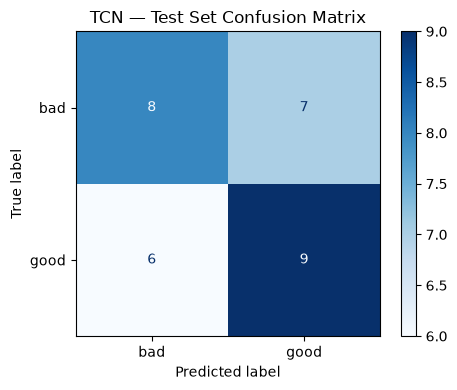


Per-view performance (TCN):
  diagonal    n= 10  macro-F1=0.5833
  front       n= 10  macro-F1=0.8000
  side        n= 10  macro-F1=0.2929


In [36]:
# Confusion Matrix (best temporal model = TCN)
primary_model = models["TCN"]
y_true, y_pred, y_prob = predict(primary_model, test_idx)

fig, ax = plt.subplots(figsize=(5, 4))
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=["bad", "good"]).plot(
    cmap="Blues", values_format="d", ax=ax
)
ax.set_title("TCN — Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

# Per-view breakdown
print("\nPer-view performance (TCN):")
for view in sorted(np.unique(views[test_idx])):
    mask = views[test_idx] == view
    view_f1 = f1_score(y_true[mask], y_pred[mask], average="macro", zero_division=0)
    print(f"  {view:10s}  n={mask.sum():3d}  macro-F1={view_f1:.4f}")

In [37]:
# Save results & artifacts

# Model comparison table
results_df.to_csv(OUT / "model_comparison.csv", index=False)
print(f"Saved: {OUT / 'model_comparison.csv'}")

# Per-clip test predictions for error analysis
test_preds_df = pd.DataFrame({
    "video_path": paths[test_idx],
    "subject_id": groups[test_idx],
    "view":       views[test_idx],
    "true":       y_true,
    "pred":       y_pred,
    "prob_good":  y_prob,
})
test_preds_df.to_csv(OUT / "test_predictions.csv", index=False)
print(f"Saved: {OUT / 'test_predictions.csv'}")

# TCN model checkpoint
torch.save(
    {
        "state_dict": primary_model.state_dict(),
        "frames": N_FRAMES,
        "labels": {"0": "bad", "1": "good"},
    },
    OUT / "tcn_squat.pt",
)
print(f"Saved: {OUT / 'tcn_squat.pt'}")

Saved: D:\DL\outputs\model_comparison.csv
Saved: D:\DL\outputs\test_predictions.csv
Saved: D:\DL\outputs\tcn_squat.pt


## 7. Grouped 5-Fold Cross-Validation

In [38]:
from sklearn.model_selection import GroupKFold

N_FOLDS = 5
gkf = GroupKFold(n_splits=N_FOLDS)
cv_results = []

for fold, (trainval_ix, test_ix) in enumerate(gkf.split(X, y, groups)):
    print(f"\n{'='*60}")
    print(f"  Fold {fold + 1}/{N_FOLDS}  |  Test subjects: {sorted(set(groups[test_ix]))}")
    print(f"{'='*60}")

    # Split trainval into train (80%) and val (20%) by subject
    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED + fold)
    rel_tr, rel_va = next(gss.split(X[trainval_ix], y[trainval_ix], groups[trainval_ix]))
    fold_tr = trainval_ix[rel_tr]
    fold_va = trainval_ix[rel_va]

    # Verify zero leakage
    assert not (set(groups[fold_tr]) & set(groups[test_ix]))
    assert not (set(groups[fold_va]) & set(groups[test_ix]))

    for name, Cls in [("MLP", MLP), ("GRU", GRU), ("TCN", TCN)]:
        torch.manual_seed(SEED + fold)
        m = Cls().to(dev)

        cc = np.bincount(y[fold_tr], minlength=2)
        wt = torch.tensor(len(fold_tr) / (2 * np.maximum(cc, 1)), dtype=torch.float32, device=dev)
        crit = nn.CrossEntropyLoss(weight=wt)
        opt = torch.optim.AdamW(m.parameters(), lr=1e-3, weight_decay=1e-3)

        best_f1, best_st, wait = -1, None, 0
        for epoch in range(60):
            m.train()
            for xb, yb in make_loader(fold_tr, True):
                xb, yb = xb.to(dev), yb.to(dev)
                opt.zero_grad(); crit(m(xb), yb).backward()
                nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step()

            m.eval(); ps, ts = [], []
            with torch.no_grad():
                for xb, yb in make_loader(fold_va):
                    ps.extend(m(xb.to(dev)).argmax(1).cpu().numpy()); ts.extend(yb.numpy())
            vf1 = f1_score(ts, ps, average="macro", zero_division=0)
            if vf1 > best_f1:
                best_f1 = vf1; best_st = {k: v.cpu().clone() for k, v in m.state_dict().items()}; wait = 0
            else:
                wait += 1
            if wait >= 10: break

        m.load_state_dict(best_st); m.eval()
        tp, tt = [], []
        with torch.no_grad():
            for xb, yb in make_loader(test_ix):
                tp.extend(m(xb.to(dev)).argmax(1).cpu().numpy()); tt.extend(yb.numpy())
        tt, tp = np.array(tt), np.array(tp)
        mf1 = f1_score(tt, tp, average="macro", zero_division=0)
        ba = balanced_accuracy_score(tt, tp)
        cv_results.append({"fold": fold+1, "model": name, "test_macro_f1": round(mf1,4), "test_bal_acc": round(ba,4), "val_f1": round(best_f1,4)})
        print(f"  {name:4s}  val-F1={best_f1:.3f}  test-F1={mf1:.3f}")

    # Majority baseline
    maj = np.full(len(test_ix), np.bincount(y[fold_tr]).argmax())
    cv_results.append({"fold": fold+1, "model": "Majority", "test_macro_f1": round(f1_score(y[test_ix], maj, average="macro", zero_division=0),4), "test_bal_acc": round(balanced_accuracy_score(y[test_ix], maj),4), "val_f1": 0.0})

print("\nCross-validation complete.")



  Fold 1/5  |  Test subjects: [np.str_('subject_005'), np.str_('subject_010'), np.str_('subject_015'), np.str_('subject_020'), np.str_('subject_026')]
  MLP   val-F1=0.438  test-F1=0.457
  GRU   val-F1=0.624  test-F1=0.800
  TCN   val-F1=0.333  test-F1=0.333

  Fold 2/5  |  Test subjects: [np.str_('subject_004'), np.str_('subject_009'), np.str_('subject_014'), np.str_('subject_019'), np.str_('subject_024')]
  MLP   val-F1=0.583  test-F1=0.428
  GRU   val-F1=0.619  test-F1=0.495
  TCN   val-F1=0.667  test-F1=0.499

  Fold 3/5  |  Test subjects: [np.str_('subject_003'), np.str_('subject_008'), np.str_('subject_013'), np.str_('subject_018'), np.str_('subject_023')]
  MLP   val-F1=0.583  test-F1=0.531
  GRU   val-F1=0.619  test-F1=0.514
  TCN   val-F1=0.788  test-F1=0.525

  Fold 4/5  |  Test subjects: [np.str_('subject_002'), np.str_('subject_007'), np.str_('subject_012'), np.str_('subject_017'), np.str_('subject_022')]
  MLP   val-F1=0.457  test-F1=0.525
  GRU   val-F1=0.608  test-F1=0.

In [39]:
cv_df = pd.DataFrame(cv_results)
summary = cv_df.groupby("model").agg(
    mean_f1=("test_macro_f1", "mean"), std_f1=("test_macro_f1", "std"),
    mean_ba=("test_bal_acc", "mean"), std_ba=("test_bal_acc", "std"),
).round(4)
summary["Macro-F1"] = summary.apply(lambda r: f"{r['mean_f1']:.3f} ± {r['std_f1']:.3f}", axis=1)
summary["Bal Acc"]  = summary.apply(lambda r: f"{r['mean_ba']:.3f} ± {r['std_ba']:.3f}", axis=1)

print("\nGrouped 5-Fold CV Results (mean ± std):")
display(summary[["Macro-F1", "Bal Acc"]].sort_values("Macro-F1", ascending=False))

# Save
cv_df.to_csv(OUT / "cv_results_per_fold.csv", index=False)
summary.to_csv(OUT / "cv_summary.csv")
print(f"\nSaved: {OUT / 'cv_results_per_fold.csv'}")



📊 Grouped 5-Fold CV Results (mean ± std):


,Macro-F1,Bal Acc
model,,
GRU,0.593 ± 0.127,0.600 ± 0.122
TCN,0.509 ± 0.109,0.560 ± 0.049
MLP,0.473 ± 0.051,0.487 ± 0.045
Majority,0.333 ± 0.000,0.500 ± 0.000



Saved: D:\DL\outputs\cv_results_per_fold.csv
